# Remunerômetro — RAIS 2025 | Aprendizagem de Máquina Supervisionada

**UFPB/CCSA · Projeto individual · 2026.2**

**Questão aplicada.** O detalhamento da ocupação melhora a predição da remuneração nominal de dezembro de 2025 de vínculos formais? São comparadas duas especificações que diferem apenas na codificação ocupacional: **A — três grupos profissionais** e **B — 35 códigos CBO**.

Este notebook documenta as decisões metodológicas e **reproduz tabelas e gráficos a partir de artefatos agregados da execução concluída**. O treinamento (script 04) e a avaliação final (script 05) são executados separadamente, sobre a base RAIS mantida fora do GitHub. Aqui **não se treina um novo modelo nem se utiliza o teste para escolher parâmetros**.

**Execução de referência:** semente numérica `45327` (últimos seis dígitos da matrícula: `045327`); Ridge com `alpha=10` em ambas as especificações.


## 1. Fontes, universo e unidade estatística

A fonte principal é a **RAIS pública 2025**. A unidade estatística é o **vínculo empregatício formal**, e não o trabalhador único; um trabalhador pode aparecer em mais de um vínculo. O universo analítico compreende 35 CBOs selecionados e três grupos: Estatística formal e quantitativas, TI e dados, Expansão profissional. Foram selecionados vínculos **ativos em 31/12/2025** e com **remuneração nominal de dezembro positiva**. O universo elegível contém **1.173.463 vínculos**.

A UF e o município se referem ao **estabelecimento empregador**, não necessariamente à residência ou ao local de trabalho remoto. A tipologia IBGE é associada a esse município.

**Fluxo implementado:** `01_preparar_rais.py` → `02_preparar_modelagem.py` → `03_auditar_base.py` → `04_treinamento.py` → `05_avaliar.py` → `06_cartografia.py` → `07_prep_data.py` → `08_exportar_public_data.py`.

Os microdados e os modelos ajustados permanecem fora deste repositório. Este notebook lê somente os arquivos agregados em `notebook/artefatos/`.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Pode ser executado a partir da raiz do repositório ou da pasta notebook/.
ATUAL = Path.cwd()
if (ATUAL / "notebook" / "artefatos").is_dir():
    ARTEFATOS = ATUAL / "notebook" / "artefatos"
elif (ATUAL / "artefatos").is_dir():
    ARTEFATOS = ATUAL / "artefatos"
else:
    raise FileNotFoundError(
        "Pasta de artefatos não encontrada. Abra a raiz do repositório "
        "ou a pasta notebook/ como diretório de trabalho."
    )

TREINO = ARTEFATOS
AVALIACAO = ARTEFATOS

def localizar(nome: str, pasta: Path) -> Path:
    caminho = pasta / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Artefato necessário ausente: {caminho}")
    return caminho

def ler_csv(nome: str, pasta: Path) -> pd.DataFrame:
    return pd.read_csv(localizar(nome, pasta), sep=";", decimal=",", encoding="utf-8-sig")

def brl(v):
    return f"R$ {v:,.2f}".replace(",", "§").replace(".", ",").replace("§", ".")

print("Artefatos encontrados:", len(list(ARTEFATOS.glob("*"))))


Artefatos encontrados: 8


## 2. Variável-alvo, atributos e pré-processamento

O alvo é `ln_rem_dez = ln(rem_dez_nom)`, definido para remuneração nominal de dezembro positiva. As previsões em log são convertidas de volta para reais pela exponencial na avaliação do MAE. O RMSE complementar é informado na escala logarítmica.

**Preditores comuns:** `uf_sigla`, `tipologia_ibge`, `escolaridade`, `cnae_divisao`, `idade` e `horas`. O sétimo atributo é **`grupo_ocupacional` no Modelo A ou `cbo` no Modelo B**. Ambas as classificações não são incluídas simultaneamente porque a primeira é determinada pela segunda, criando redundância. `rem_media_nom` não é utilizada como preditora, pois sua disponibilidade e proximidade com o alvo podem gerar vazamento de informação.

As variáveis categóricas recebem imputação de uma categoria constante e codificação one-hot; as numéricas recebem imputação pela mediana (com indicador de ausência) e padronização. Essas transformações são ajustadas **dentro de cada treinamento/fold**, por meio de `Pipeline` e `ColumnTransformer`, evitando vazamento dos dados de validação e teste. A função abaixo reproduz a *configuração* usada no script 04, mas não ajusta um novo estimador.


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORICAS = ["uf_sigla", "tipologia_ibge", "escolaridade", "cnae_divisao"]
NUMERICAS = ["idade", "horas"]

def pre_processador(variavel_ocupacional: str):
    cat = Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="Ausente")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=True)),
    ])
    num = Pipeline([
        ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalar", StandardScaler()),
    ])
    return ColumnTransformer([
        ("categoricas", cat, [variavel_ocupacional] + CATEGORICAS),
        ("numericas", num, NUMERICAS),
    ], sparse_threshold=0.3)

print("Modelo A:", ["grupo_ocupacional"] + CATEGORICAS + NUMERICAS)
print("Modelo B:", ["cbo"] + CATEGORICAS + NUMERICAS)


Modelo A: ['grupo_ocupacional', 'uf_sigla', 'tipologia_ibge', 'escolaridade', 'cnae_divisao', 'idade', 'horas']
Modelo B: ['cbo', 'uf_sigla', 'tipologia_ibge', 'escolaridade', 'cnae_divisao', 'idade', 'horas']


## 3. Partição, amostra e validação cruzada

A divisão foi de **80% para treinamento** (**938.770 vínculos**) e **20% para teste** (**234.693 vínculos**). Apenas **2.000 vínculos**, sorteados da parcela de treinamento, foram utilizados para ajuste e validação cruzada com **cinco dobras** (`KFold`, com embaralhamento).

A semente numérica é **`45327`**, correspondente à matrícula terminada em **`045327`**. Os algoritmos comparados foram baseline (`DummyRegressor`), regressão linear por MQO, Ridge e Lasso. Para Ridge e Lasso, a grade de `alpha` variou de 10⁻⁴ a 10⁴. A escolha seguiu exclusivamente o **menor MAE médio de validação cruzada em reais**.

O teste final não participou dessa escolha. A avaliação na etapa 05 utiliza os estimadores e a partição congelados na etapa 04, sem novo ajuste de hiperparâmetros.


In [3]:
meta = json.loads(localizar("metadados_treino.json", TREINO).read_text(encoding="utf-8-sig"))
assert meta["semente"] == 45327, "Metadados não correspondem à execução definitiva."
assert meta["n_amostra"] == 2000 and meta["n_teste_intocado"] == 234693
assert all(v["algoritmo"] == "ridge" and v["alpha"] == 10.0 for v in meta["selecionados_cv"].values())
display(pd.DataFrame([{
    "Semente": meta["semente"],
    "Vínculos elegíveis": meta["n_populacao"],
    "Treinamento disponível": meta["n_treino_populacao"],
    "Amostra para modelagem": meta["n_amostra"],
    "Vínculos de teste": meta["n_teste_intocado"],
    "Dobras": meta["dobras"],
}]))


,Semente,Vínculos elegíveis,Treinamento disponível,Amostra para modelagem,Vínculos de teste,Dobras
0,45327,1173463,938770,2000,234693,5


## 4. Comparação dos modelos por validação cruzada

O desempenho abaixo foi calculado pelo script 04 sobre os **2.000 vínculos de modelagem** e não sobre o teste. As diferenças pequenas entre Ridge e Lasso não demonstram superioridade estatística universal; Ridge foi selecionado porque obteve o menor MAE médio na grade previamente avaliada.


,especificacao,algoritmo,alpha,mae_treino,mae_cv_media,mae_cv_dp,rmse_log_cv_media
0,cbos,ridge,10.000,4080.774661,4230.233088,309.793913,0.587624
1,cbos,lasso,0.001,4072.207392,4231.719230,298.856470,0.588346
2,cbos,mqo,NaN,3984.395276,4288.319701,295.181116,0.597653
3,cbos,baseline,NaN,5269.536253,5272.042813,319.577960,0.739167
4,familias,ridge,10.000,4309.000656,4432.365091,281.252456,0.611961
5,familias,lasso,0.001,4308.889162,4436.345579,277.742558,0.614006
6,familias,mqo,NaN,4218.610801,4451.176673,277.360253,0.617253
7,familias,baseline,NaN,5269.536253,5272.042813,319.577960,0.739167


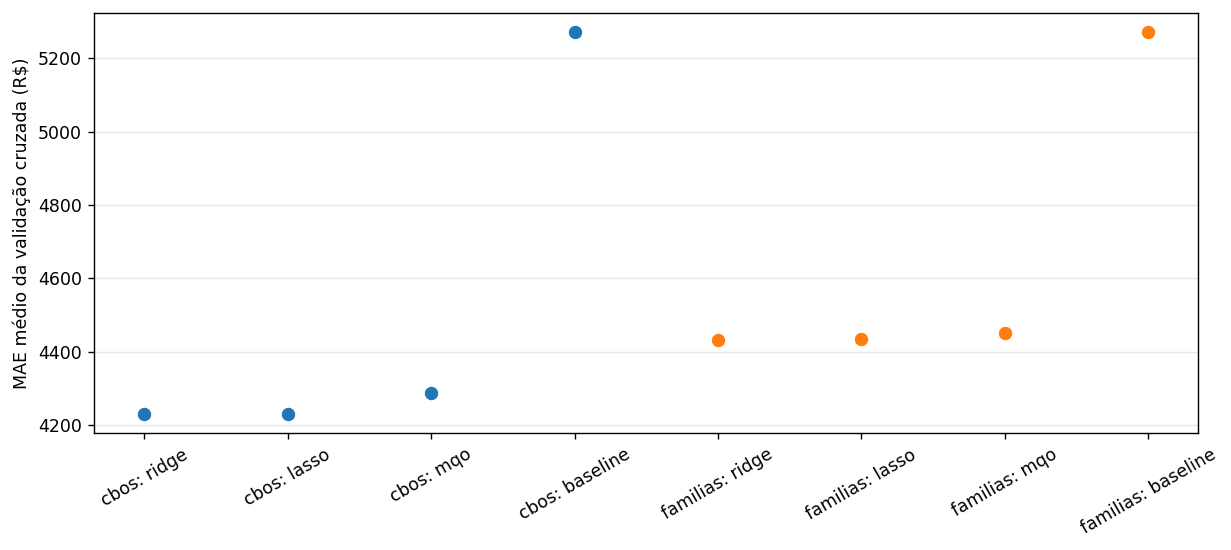

In [4]:
cv = ler_csv("comparacao_validacao_cruzada.csv", TREINO)
cols = ["especificacao", "algoritmo", "alpha", "mae_treino", "mae_cv_media", "mae_cv_dp", "rmse_log_cv_media"]
display(cv[cols].sort_values(["especificacao", "mae_cv_media"]).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 4.5))
for especificacao, grupo in cv.groupby("especificacao"):
    melhores = grupo.sort_values("mae_cv_media").head(4)
    labels = [f"{especificacao}: {alg}" for alg in melhores["algoritmo"]]
    ax.scatter(labels, melhores["mae_cv_media"], label=especificacao, s=45)
ax.set_ylabel("MAE médio da validação cruzada (R$)")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Sensibilidade à regularização

As curvas representam a grade de valores de `alpha` avaliada na etapa 04. O notebook apenas apresenta os resultados registrados; **não realiza nova seleção após observar o teste**.


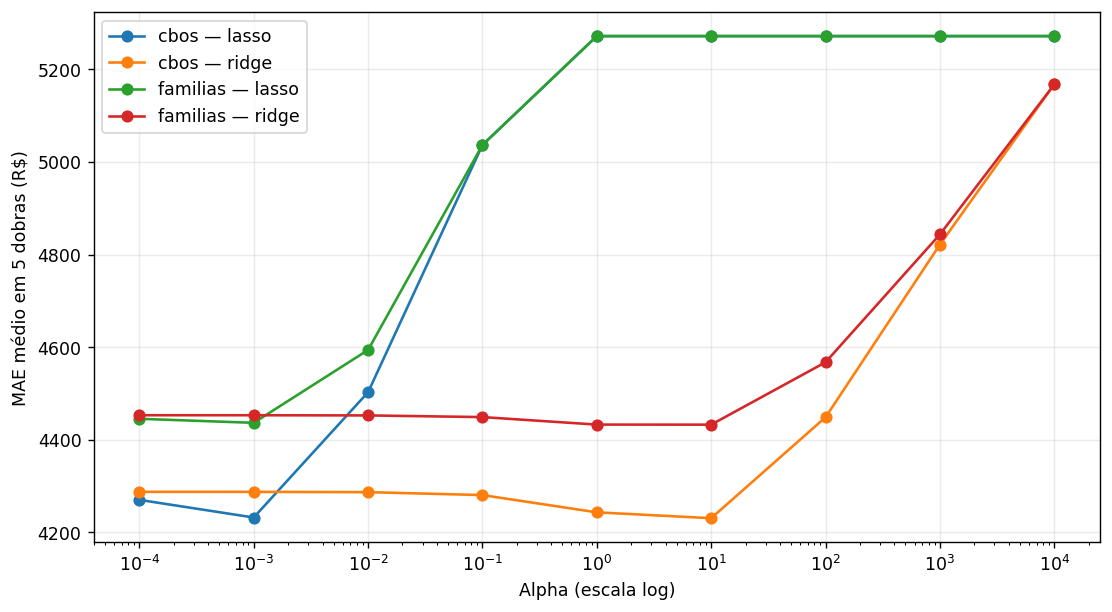

In [5]:
curvas = ler_csv("curvas_validacao.csv", TREINO)
fig, ax = plt.subplots(figsize=(9, 5))
for (modelo, algoritmo), grupo in curvas.groupby(["especificacao", "algoritmo"]):
    if algoritmo in ("lasso", "ridge"):
        ax.plot(grupo["alpha"], grupo["mae_cv_media"], marker="o", label=f"{modelo} — {algoritmo}")
ax.set_xscale("log")
ax.set_xlabel("Alpha (escala log)")
ax.set_ylabel("MAE médio em 5 dobras (R$)")
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()


## 6. Complexidade e seleção das especificações

Na execução definitiva, o **Modelo A (famílias) utilizou 107 atributos transformados**, enquanto o **Modelo B (35 CBOs) utilizou 137**. Com 2.000 observações de treinamento, isso corresponde a relações `p/n` de **5,35%** e **6,85%**. A maior granularidade pode ajudar a prever diferenças entre ocupações, mas demanda mais parâmetros e pode tornar estimativas de ocupações raras menos estáveis.

A validação cruzada selecionou **Ridge (`alpha=10`) para os dois modelos**. Ridge utiliza penalização L2, que contrai os coeficientes sem normalmente zerá-los. O Lasso utiliza L1 e pode zerar coeficientes. A comparação é **preditiva**, não causal.


In [6]:
selecionados = meta["selecionados_cv"]
display(pd.DataFrame([
    {"Especificação": nome, "Algoritmo": v["algoritmo"], "Alpha": v["alpha"],
     "p": v["p"], "n": v["n"], "p/n": v["p_sobre_n"], "MAE CV (R$)": v["mae_cv"]}
    for nome, v in selecionados.items()
]))


,Especificação,Algoritmo,Alpha,p,n,p/n,MAE CV (R$)
0,familias,ridge,10.0,107,2000,0.0535,4432.365091
1,cbos,ridge,10.0,137,2000,0.0685,4230.233088


## 7. Avaliação final sobre o conjunto de teste congelado

**Esta seção lê exclusivamente `01_metricas_finais.csv`, produzido pelo script 05.** Não abre os índices da partição, não carrega os modelos individuais e não retreina estimadores.

A avaliação final foi realizada sobre **234.693 vínculos de teste**, após a seleção exclusiva por validação cruzada. Valores exibidos aqui são resultados descritivos dessa partição.


,especificacao,algoritmo_congelado_cv,alpha_congelado_cv,n_teste,mae_cv_2mil_reais,mae_teste_reais,rmse_teste_log,vies_medio_reais_previsto_menos_observado,p_sobre_n_amostra
0,familias,ridge,10.0,234693,4432.365091,4337.177399,0.617272,-1669.379785,0.0535
1,cbos,ridge,10.0,234693,4230.233088,4143.405201,0.589055,-1550.996261,0.0685


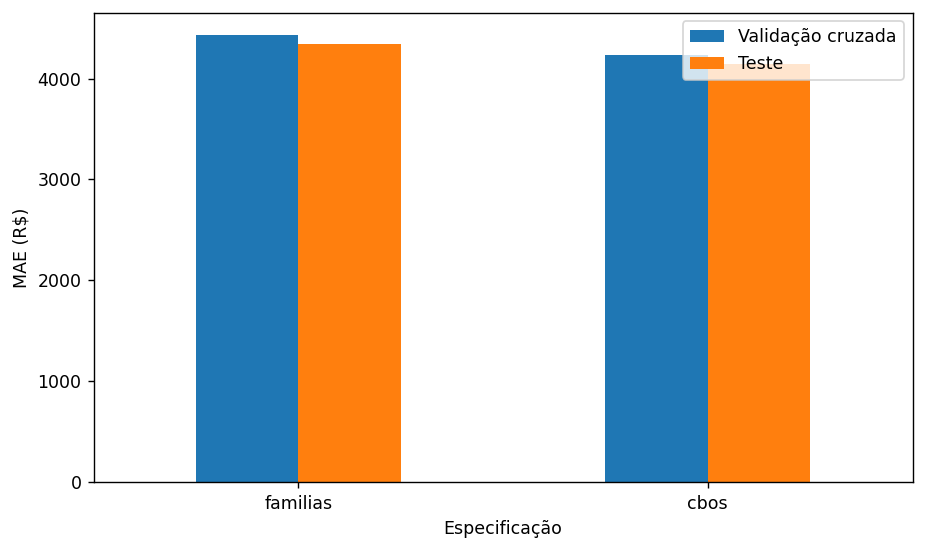

In [7]:
final = ler_csv("01_metricas_finais.csv", AVALIACAO)
assert set(final["especificacao"]) == {"familias", "cbos"}
assert set(final["algoritmo_congelado_cv"]) == {"ridge"}
assert set(final["alpha_congelado_cv"]) == {10.0}
mostra = ["especificacao", "algoritmo_congelado_cv", "alpha_congelado_cv", "n_teste",
         "mae_cv_2mil_reais", "mae_teste_reais", "rmse_teste_log",
         "vies_medio_reais_previsto_menos_observado", "p_sobre_n_amostra"]
display(final[mostra])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
final.plot(x="especificacao", y=["mae_cv_2mil_reais", "mae_teste_reais"], kind="bar", ax=ax)
ax.set_ylabel("MAE (R$)")
ax.set_xlabel("Especificação")
ax.legend(["Validação cruzada", "Teste"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. Diagnósticos por subgrupos

Os arquivos de avaliação contêm métricas por sexo, escolaridade e grupo ocupacional. O MAE em reais pode ser maior em grupos de remuneração mais elevada, sem que isso signifique necessariamente pior erro relativo. Grupos raros demandam cautela na interpretação. Diferenças de desempenho entre grupos **não identificam discriminação causal**.


In [8]:
for nome in ["03_erros_por_sexo.csv", "03_erros_por_escolaridade.csv", "03_erros_por_grupo_ocupacional.csv"]:
    caminho = AVALIACAO / nome
    if caminho.is_file():
        print("\n", nome)
        display(ler_csv(nome, AVALIACAO).head(30))
    else:
        print(f"Diagnóstico opcional não incluído: {nome}")



 03_erros_por_sexo.csv


,especificacao,variavel,categoria,n,n_minimo_30,mae_teste_reais,rmse_teste_log,remuneracao_media_real,previsao_media_reais
0,familias,sexo,2,94435,True,3544.330701,0.584485,7773.475139,6960.536096
1,familias,sexo,1,140258,True,4870.997059,0.638400,10178.898799,7932.881807
2,cbos,sexo,2,94435,True,3427.161598,0.565681,7773.475139,7063.009888
3,cbos,sexo,1,140258,True,4625.648386,0.604283,10178.898799,8061.977273



 03_erros_por_escolaridade.csv


,especificacao,variavel,categoria,n,n_minimo_30,mae_teste_reais,rmse_teste_log,remuneracao_media_real,previsao_media_reais
0,familias,escolaridade,9,229662,True,4220.405569,0.616009,8970.321708,7381.042105
1,familias,escolaridade,10,4114,True,9602.149226,0.665200,20302.234152,14827.003635
2,familias,escolaridade,11,917,True,9961.995139,0.703967,19732.494209,15076.529923
3,cbos,escolaridade,9,229662,True,4030.036070,0.587672,8970.321708,7503.717069
4,cbos,escolaridade,10,4114,True,9302.890755,0.645640,20302.234152,14753.548179
5,cbos,escolaridade,11,917,True,9389.269623,0.664162,19732.494209,14980.785553



 03_erros_por_grupo_ocupacional.csv


,especificacao,variavel,categoria,n,n_minimo_30,mae_teste_reais,rmse_teste_log,remuneracao_media_real,previsao_media_reais
0,familias,grupo_ocupacional,Estatística formal e quantitativas,2894,True,5922.777134,0.635167,12166.145356,9649.521780
1,familias,grupo_ocupacional,Expansão profissional,125063,True,3974.690708,0.600331,8403.796328,6699.170782
2,familias,grupo_ocupacional,TI e dados,106736,True,4718.913153,0.636072,10076.706151,8471.595818
3,cbos,grupo_ocupacional,Estatística formal e quantitativas,2894,True,5830.106086,0.635837,12166.145356,8957.420761
4,cbos,grupo_ocupacional,Expansão profissional,125063,True,3868.037283,0.586401,8403.796328,6886.282575
5,cbos,grupo_ocupacional,TI e dados,106736,True,4420.322319,0.590835,10076.706151,8531.425327


## 9. Interpretação dos resultados e limitações

O **Modelo A — Famílias (Ridge, α=10)** registrou **MAE de R$ 4.337,18** e **RMSE(log) de 0,6173** no teste. O **Modelo B — 35 CBOs (Ridge, α=10)** alcançou **MAE de R$ 4.143,41** e **RMSE(log) de 0,5891**. A diferença observada é de **R$ 193,77**, equivalente a **4,47% de redução no MAE** em favor do detalhamento por CBO.

A remuneração média observada no teste foi **R$ 9.211,01**. As médias previstas foram **R$ 7.541,63** (Famílias) e **R$ 7.660,02** (CBOs). Os vieses médios, definidos como previsão menos valor observado, foram aproximadamente **−R$ 1.669,38** e **−R$ 1.551,00**. Uma fonte possível de subestimação é a retrans formação não linear: a exponencial da média condicional do logaritmo não coincide necessariamente com a média condicional em reais. Isso não comprova que toda a diferença se deva à transformação.

A comparação não permite inferência causal sobre remuneração. O recorte cobre vínculos formais de um mês específico, excluindo grande parte do trabalho autônomo e informal. A modelagem utiliza apenas 2.000 observações de treinamento, com possível representação limitada de ocupações raras. A unidade geográfica é o estabelecimento e não a residência.

O dashboard público apresenta **somente células agregadas de território × CBO com pelo menos 30 vínculos**; por isso, suas métricas e seus totais podem diferir dos valores do **teste completo** mostrados acima. O limiar de divulgação não garante sozinho ausência de risco de inferência por filtros.


## 10. Reprodutibilidade, integridade e apoio de IA

A rastreabilidade da modelagem é sustentada pelos metadados, índices de partição, pipelines persistidos e marcador da avaliação final produzidos pelos scripts 04 e 05. **O GitHub publica os códigos e os artefatos agregados, mas não os microdados RAIS, os índices de teste ou os modelos binários.** Para reproduzir o processamento completo, é necessário obter os dados da fonte e configurar o diretório externo via `REMUNEROMETRO_DATA`, conforme o README. Para reproduzir **as tabelas e figuras deste notebook**, bastam os arquivos de `notebook/artefatos/`.

**Uso de ferramentas de IA:** foram empregadas como apoio à escrita e revisão de código e documentação. As decisões analíticas, a conferência dos dados e a interpretação final são de responsabilidade do autor.